# Module 2 — Data Exploration (TED Talks Recommendation System)

**Notebook:** `01_Data_Exploration.ipynb`  
**Project:** Personalized TED Talks Recommendation System Using Machine Learning

## Objectives
1. Understand the structure and quality of the collected TED dataset.
2. Measure missing values, duplicates, inconsistent values, and data types.
3. Explore talk duration, views, comments, publication dates, speakers, and topics.
4. Explore transcript and description text without modifying the raw dataset.
5. Identify whether the available data supports content-based and collaborative recommendation.

**Important:** This notebook is for exploration only. It does not clean or overwrite the raw CSV, train a model, create TF-IDF vectors, or generate the final processed dataset. Those tasks belong in the preprocessing and feature-engineering modules.

## 1. Import libraries

Install missing libraries in your environment if needed:

```bash
pip install pandas numpy matplotlib seaborn
```

In [1]:
from pathlib import Path
import ast
import re
import json
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

## 2. Locate project files and create output folders

The notebook searches upward from its own location for `Scraped/Data/Raw/ted_talks.csv`.  
If the notebook is being run outside the repository, set `PROJECT_ROOT` manually in the cell below.

In [2]:
# Option A: automatic project-root detection
current = Path.cwd()
PROJECT_ROOT = None

for candidate in [current, *current.parents]:
    expected = candidate / "Scraped" / "Data" / "Raw" / "ted_talks.csv"
    if expected.exists():
        PROJECT_ROOT = candidate
        break

# Option B: manually set your project folder if automatic detection fails:
# PROJECT_ROOT = Path(r"C:\Users\YourName\path\to\Infosys-SpringBoard-Internship")

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate Scraped/Data/Raw/ted_talks.csv. "
        "Set PROJECT_ROOT manually to your repository folder."
    )

RAW_DIR = PROJECT_ROOT / "Scraped" / "Data" / "Raw"
OUTPUT_DIR = PROJECT_ROOT / "Module_2_Data_Exploration_Preprocessing" / "outputs"
PLOT_DIR = OUTPUT_DIR / "visualizations"
REPORT_DIR = OUTPUT_DIR / "reports"
STATS_DIR = OUTPUT_DIR / "statistics"

for folder in [PLOT_DIR, REPORT_DIR, STATS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

MAIN_PATH = RAW_DIR / "ted_talks.csv"
TED_MAIN_PATH = RAW_DIR / "ted_main.csv"
TRANSCRIPTS_PATH = RAW_DIR / "transcripts.csv"
CLEAN_PATH = PROJECT_ROOT / "Scraped" / "Data" / "Processed" / "ted_talks_clean.csv"

print("Project root:", PROJECT_ROOT)
print("Primary dataset:", MAIN_PATH)
print("Output folder:", OUTPUT_DIR)

Project root: c:\Users\DELL\Desktop\INTERNSHIPS\Infosys_SpringBoard\Ted_Talk_Recommendation
Primary dataset: c:\Users\DELL\Desktop\INTERNSHIPS\Infosys_SpringBoard\Ted_Talk_Recommendation\Scraped\Data\Raw\ted_talks.csv
Output folder: c:\Users\DELL\Desktop\INTERNSHIPS\Infosys_SpringBoard\Ted_Talk_Recommendation\Module_2_Data_Exploration_Preprocessing\outputs


## 3. Load the primary dataset

`ted_talks.csv` is the primary source for this notebook because it contains the combined talk metadata and transcript fields. We load it without changing the source file.

In [3]:
if not MAIN_PATH.exists():
    raise FileNotFoundError(f"Primary dataset not found: {MAIN_PATH}")

df = pd.read_csv(MAIN_PATH, low_memory=False)
df_original = df.copy(deep=True)

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Dataset shape: 2,550 rows × 20 columns


,talk_id,title,main_speaker,speaker_occupation,description,tags,transcript,related_talks,ratings,views,comments,duration,published_date,event,url,source,film_date,languages,name,num_speaker
0,1,Do schools kill creativity?,Ken Robinson,Author/educator,Sir Ken Robinson makes an entertaining and profoundly moving case for creating an education system that nurtures (ra...,"['children', 'creativity', 'culture', 'dance', 'education', 'parenting', 'teaching']","Good morning. How are you?(Laughter)It's been great, hasn't it? I've been blown away by the whole thing. In fact, I'...","[{'id': 865, 'hero': 'https://pe.tedcdn.com/images/ted/172559_800x600.jpg', 'speaker': 'Ken Robinson', 'title': 'Bri...","[{'id': 7, 'name': 'Funny', 'count': 19645}, {'id': 1, 'name': 'Beautiful', 'count': 4573}, {'id': 9, 'name': 'Ingen...",47227110,4553,1164,1151367060,TED2006,https://www.ted.com/talks/ken_robinson_says_schools_kill_creativity,TED_Public_Archive_CC_BY_NC_SA_4.0,1140825600,60,Ken Robinson: Do schools kill creativity?,1
1,2,Averting the climate crisis,Al Gore,Climate advocate,"With the same humor and humanity he exuded in ""An Inconvenient Truth,"" Al Gore spells out 15 ways that individuals c...","['alternative energy', 'cars', 'climate change', 'culture', 'environment', 'global issues', 'science', 'sustainabili...","Thank you so much, Chris. And it's truly a great honor to have the opportunity to come to this stage twice; I'm extr...","[{'id': 243, 'hero': 'https://pe.tedcdn.com/images/ted/566c14767bd62c5ff760e483c5b16cd2753328cd_2880x1620.jpg', 'spe...","[{'id': 7, 'name': 'Funny', 'count': 544}, {'id': 3, 'name': 'Courageous', 'count': 139}, {'id': 2, 'name': 'Confusi...",3200520,265,977,1151367060,TED2006,https://www.ted.com/talks/al_gore_on_averting_climate_crisis,TED_Public_Archive_CC_BY_NC_SA_4.0,1140825600,43,Al Gore: Averting the climate crisis,1
2,3,Simplicity sells,David Pogue,Technology columnist,"New York Times columnist David Pogue takes aim at technology’s worst interface-design offenders, and provides encour...","['computers', 'entertainment', 'interface design', 'media', 'music', 'performance', 'simplicity', 'software', 'techn...","(Music: ""The Sound of Silence,"" Simon & Garfunkel)Hello voice mail, my old friend.(Laughter)I've called for tech sup...","[{'id': 1725, 'hero': 'https://pe.tedcdn.com/images/ted/b7f415a054cc0a2bfdd90d0ad5a7f64cf060150d_1600x1200.jpg', 'sp...","[{'id': 7, 'name': 'Funny', 'count': 964}, {'id': 3, 'name': 'Courageous', 'count': 45}, {'id': 9, 'name': 'Ingeniou...",1636292,124,1286,1151367060,TED2006,https://www.ted.com/talks/david_pogue_says_simplicity_sells,TED_Public_Archive_CC_BY_NC_SA_4.0,1140739200,26,David Pogue: Simplicity sells,1
3,4,Greening the ghetto,Majora Carter,Activist for environmental justice,"In an emotionally charged talk, MacArthur-winning activist Majora Carter details her fight for environmental justice...","['MacArthur grant', 'activism', 'business', 'cities', 'environment', 'green', 'inequality', 'politics', 'pollution']",If you're here today — and I'm very happy that you are — you've all heard about how sustainable development will sav...,"[{'id': 1041, 'hero': 'https://pe.tedcdn.com/images/ted/96c703bb13a2e9c2d351a5e6b52390bc35eaad06_800x600.jpg', 'spea...","[{'id': 3, 'name': 'Courageous', 'count': 760}, {'id': 1, 'name': 'Beautiful', 'count': 291}, {'id': 2, 'name': 'Con...",1697550,200,1116,1151367060,TED2006,https://www.ted.com/talks/majora_carter_s_tale_of_urban_renewal,TED_Public_Archive_CC_BY_NC_SA_4.0,1140912000,35,Majora Carter: Greening the ghetto,1
4,5,The best stats you've ever seen,Hans Rosling,Global health expert; data visionary,"You've never seen data presented like this. With the drama and urgency of a sportscaster, statistics guru Hans Rosli...","['Africa', 'Asia', 'Google', 'demo', 'economics', 'global development', 'global issues', 'health', 'math', 'statisti...","About 10 years ago, I took on the task to teach global development to Swedish undergra

## 4. Inspect structure and data types

This section checks the schema, inferred data types, memory usage, and basic descriptive statistics.

In [4]:
print("COLUMN NAMES")
print(df.columns.tolist())

print("\nDATA TYPES")
display(df.dtypes.rename("data_type").to_frame())

print("\nDATASET INFORMATION")
df.info()

print("\nNUMERICAL SUMMARY")
display(df.describe().T)

print("\nCATEGORICAL SUMMARY")
display(df.describe(include="object").T)

COLUMN NAMES
['talk_id', 'title', 'main_speaker', 'speaker_occupation', 'description', 'tags', 'transcript', 'related_talks', 'ratings', 'views', 'comments', 'duration', 'published_date', 'event', 'url', 'source', 'film_date', 'languages', 'name', 'num_speaker']

DATA TYPES


,data_type
talk_id,int64
title,str
main_speaker,str
speaker_occupation,str
description,str
tags,str
transcript,str
related_talks,str
ratings,str
views,int64



DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 2550 entries, 0 to 2549
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   talk_id             2550 non-null   int64
 1   title               2550 non-null   str  
 2   main_speaker        2550 non-null   str  
 3   speaker_occupation  2544 non-null   str  
 4   description         2550 non-null   str  
 5   tags                2550 non-null   str  
 6   transcript          2464 non-null   str  
 7   related_talks       2550 non-null   str  
 8   ratings             2550 non-null   str  
 9   views               2550 non-null   int64
 10  comments            2550 non-null   int64
 11  duration            2550 non-null   int64
 12  published_date      2550 non-null   int64
 13  event               2550 non-null   str  
 14  url                 2550 non-null   str  
 15  source              2550 non-null   str  
 16  film_date           2550 non-nul

,count,mean,std,min,25%,50%,75%,max
talk_id,2550.0,1.275500e+03,7.362659e+02,1.000000e+00,6.382500e+02,1.275500e+03,1.912750e+03,2.550000e+03
views,2550.0,1.698297e+06,2.498479e+06,5.044300e+04,7.557928e+05,1.124524e+06,1.700760e+06,4.722711e+07
comments,2550.0,1.915624e+02,2.823152e+02,2.000000e+00,6.300000e+01,1.180000e+02,2.217500e+02,6.404000e+03
duration,2550.0,8.265102e+02,3.740091e+02,1.350000e+02,5.770000e+02,8.480000e+02,1.046750e+03,5.256000e+03
published_date,2550.0,1.343525e+09,9.464009e+07,1.151367e+09,1.268463e+09,1.340935e+09,1.423432e+09,1.506092e+09
film_date,2550.0,1.321928e+09,1.197391e+08,7.464960e+07,1.257466e+09,1.333238e+09,1.412964e+09,1.503792e+09
languages,2550.0,2.732627e+01,9.563452e+00,0.000000e+00,2.300000e+01,2.800000e+01,3.300000e+01,7.200000e+01
num_speaker,2550.0,1.028235e+00,2.077047e-01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,5.000000e+00



CATEGORICAL SUMMARY


,count,unique,top,freq
title,2550,2550,Do schools kill creativity?,1
main_speaker,2550,2156,Hans Rosling,9
speaker_occupation,2544,1458,Writer,45
description,2550,2550,Sir Ken Robinson makes an entertaining and profoundly moving case for creating an education system that nurtures (ra...,1
tags,2550,2530,"['entertainment', 'live music', 'music', 'performance']",3
transcript,2464,2464,"Good morning. How are you?(Laughter)It's been great, hasn't it? I've been blown away by the whole thing. In fact, I'...",1
related_talks,2550,2550,"[{'id': 865, 'hero': 'https://pe.tedcdn.com/images/ted/172559_800x600.jpg', 'speaker': 'Ken Robinson', 'title': 'Bri...",1
ratings,2550,2550,"[{'id': 7, 'name': 'Funny', 'count': 19645}, {'id': 1, 'name': 'Beautiful', 'count': 4573}, {'id': 9, 'name': 'Ingen...",1
event,2550,355,TED2014,84
url,2550,2550,https://www.ted.com/talks/ken_robinson_says_schools_kill_creativity,1


## 5. Data completeness and missing-value analysis

Empty strings and whitespace-only strings are counted separately from Pandas null values. This is an inspection only; no values are filled or deleted.

,column,null_count,empty_string_count,total_missing_or_empty,missing_percent
6,transcript,86,0,86,3.37
3,speaker_occupation,6,0,6,0.24
1,title,0,0,0,0.00
0,talk_id,0,0,0,0.00
2,main_speaker,0,0,0,0.00
4,description,0,0,0,0.00
5,tags,0,0,0,0.00
7,related_talks,0,0,0,0.00
8,ratings,0,0,0,0.00
9,views,0,0,0,0.00


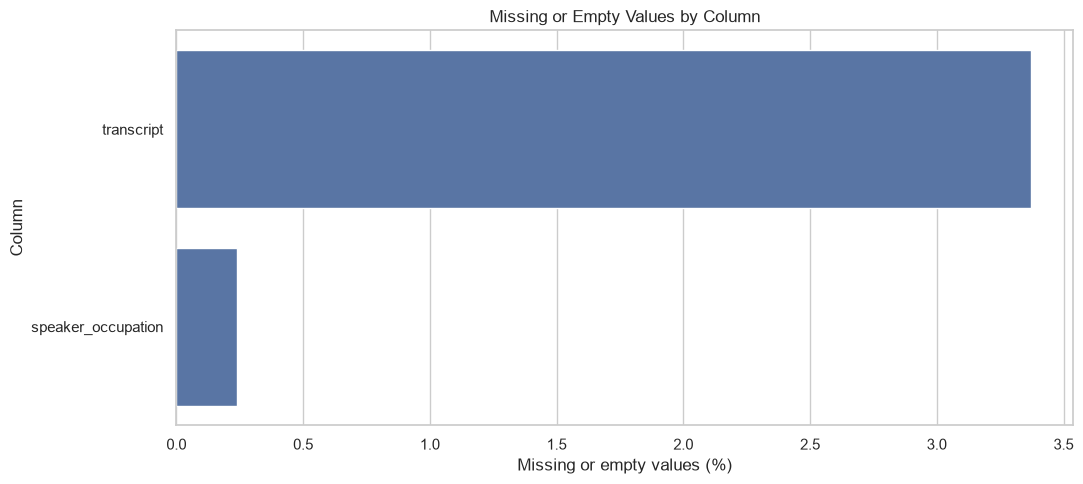

In [5]:
missing_rows = []
for col in df.columns:
    null_count = int(df[col].isna().sum())
    if df[col].dtype == "object":
        empty_count = int(df[col].astype("string").str.strip().eq("").sum())
    else:
        empty_count = 0
    missing_rows.append({
        "column": col,
        "null_count": null_count,
        "empty_string_count": empty_count,
        "total_missing_or_empty": null_count + empty_count,
        "missing_percent": round((null_count + empty_count) / len(df) * 100, 2)
    })

missing_summary = pd.DataFrame(missing_rows).sort_values(
    "missing_percent", ascending=False
)
display(missing_summary)

missing_summary.to_csv(STATS_DIR / "missing_value_summary.csv", index=False)

missing_plot = missing_summary.query("total_missing_or_empty > 0")
if not missing_plot.empty:
    plt.figure(figsize=(11, 5))
    sns.barplot(data=missing_plot, x="missing_percent", y="column")
    plt.title("Missing or Empty Values by Column")
    plt.xlabel("Missing or empty values (%)")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "01_missing_values.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("No missing or empty values detected.")

## 6. Duplicate and identifier checks

Check exact duplicate rows and duplicate identifiers/URLs. Do not remove records in this notebook.

In [6]:
duplicate_rows = int(df.duplicated().sum())

identifier_checks = {}
for col in ["talk_id", "url", "title"]:
    if col in df.columns:
        identifier_checks[col] = {
            "duplicate_count": int(df[col].astype("string").str.strip().duplicated().sum()),
            "missing_count": int(df[col].isna().sum())
        }

print("Exact duplicate rows:", duplicate_rows)
print("Identifier checks:")
display(pd.DataFrame(identifier_checks).T)

if "url" in df.columns:
    url_series = df["url"].astype("string").str.strip()
    invalid_url_count = int((~url_series.str.match(
        r"^https?://(www\.)?ted\.com/talks/", na=False
    )).sum())
    print("URLs outside expected TED talks URL pattern:", invalid_url_count)

Exact duplicate rows: 0
Identifier checks:


,duplicate_count,missing_count
talk_id,0,0
url,0,0
title,0,0


URLs outside expected TED talks URL pattern: 0


## 7. Numeric feature exploration

Explore views, comments, duration, language count, and speaker count when those columns exist. Duration is stored in seconds; we create a temporary minutes column for analysis only.

,count,mean,std,min,25%,50%,75%,max
views,2550.0,1.698297e+06,2.498479e+06,50443.0,755792.75,1124523.5,1700759.50,47227110.0
comments,2550.0,1.915624e+02,2.823152e+02,2.0,63.00,118.0,221.75,6404.0
duration,2550.0,8.265102e+02,3.740091e+02,135.0,577.00,848.0,1046.75,5256.0
languages,2550.0,2.732627e+01,9.563452e+00,0.0,23.00,28.0,33.00,72.0
num_speaker,2550.0,1.028235e+00,2.077047e-01,1.0,1.00,1.0,1.00,5.0
talk_id,2550.0,1.275500e+03,7.362659e+02,1.0,638.25,1275.5,1912.75,2550.0


Duration (minutes) summary:


,duration_minutes
count,2550.000000
mean,13.775170
std,6.233486
min,2.250000
25%,9.616667
50%,14.133333
75%,17.445833
max,87.600000


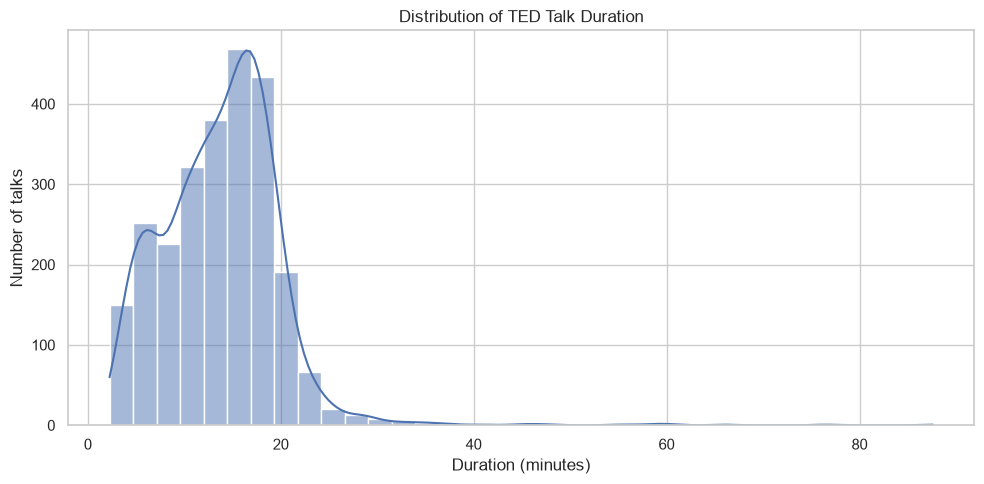

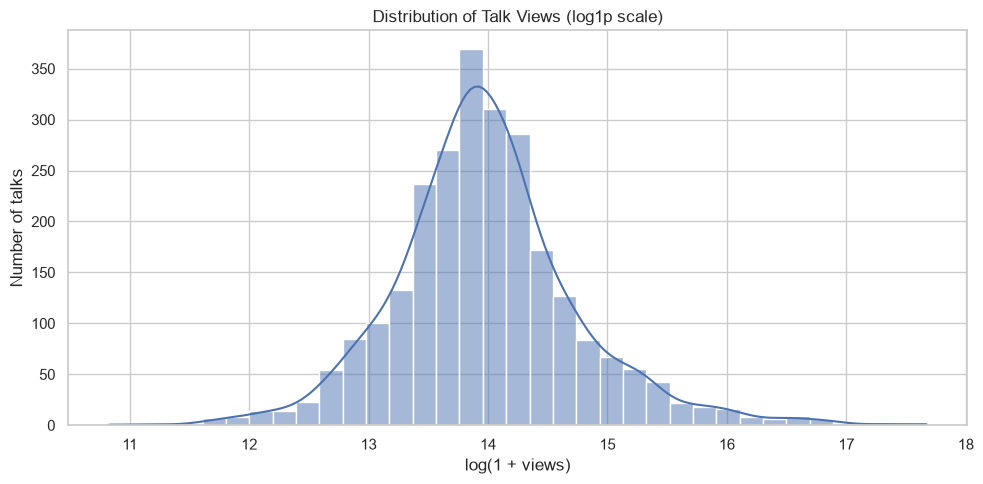

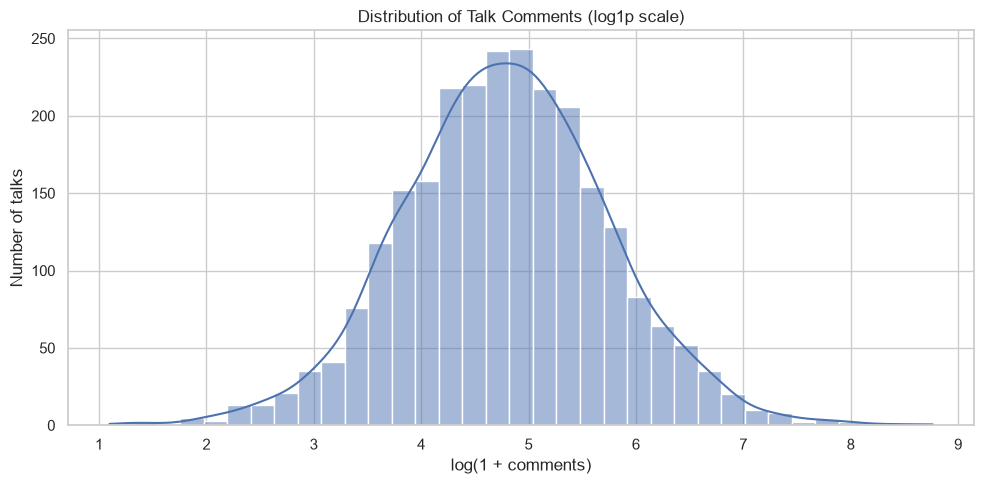

In [7]:
numeric_candidates = [
    "views", "comments", "duration", "languages",
    "num_speaker", "talk_id"
]
numeric_cols = [c for c in numeric_candidates if c in df.columns]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

display(df[numeric_cols].describe().T)

if "duration" in df.columns:
    duration_minutes = df["duration"] / 60
    print("Duration (minutes) summary:")
    display(duration_minutes.describe().to_frame("duration_minutes"))

    plt.figure(figsize=(10, 5))
    sns.histplot(duration_minutes.dropna(), bins=35, kde=True)
    plt.title("Distribution of TED Talk Duration")
    plt.xlabel("Duration (minutes)")
    plt.ylabel("Number of talks")
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "02_talk_duration_distribution.png", dpi=300, bbox_inches="tight")
    plt.show()

for col, title, filename in [
    ("views", "Distribution of Talk Views", "03_views_distribution.png"),
    ("comments", "Distribution of Talk Comments", "04_comments_distribution.png")
]:
    if col in df.columns:
        values = df[col].dropna()
        plt.figure(figsize=(10, 5))
        sns.histplot(np.log1p(values), bins=35, kde=True)
        plt.title(title + " (log1p scale)")
        plt.xlabel(f"log(1 + {col})")
        plt.ylabel("Number of talks")
        plt.tight_layout()
        plt.savefig(PLOT_DIR / filename, dpi=300, bbox_inches="tight")
        plt.show()

## 8. Views, comments, and duration relationships

Correlation is calculated only for available numeric columns. Remember that correlation does not prove causation.

,views,comments,duration,languages,num_speaker
views,1.000000,0.530939,0.048740,0.377623,-0.026389
comments,0.530939,1.000000,0.140694,0.318284,-0.035489
duration,0.048740,0.140694,1.000000,-0.295681,0.022257
languages,0.377623,0.318284,-0.295681,1.000000,-0.063100
num_speaker,-0.026389,-0.035489,0.022257,-0.063100,1.000000


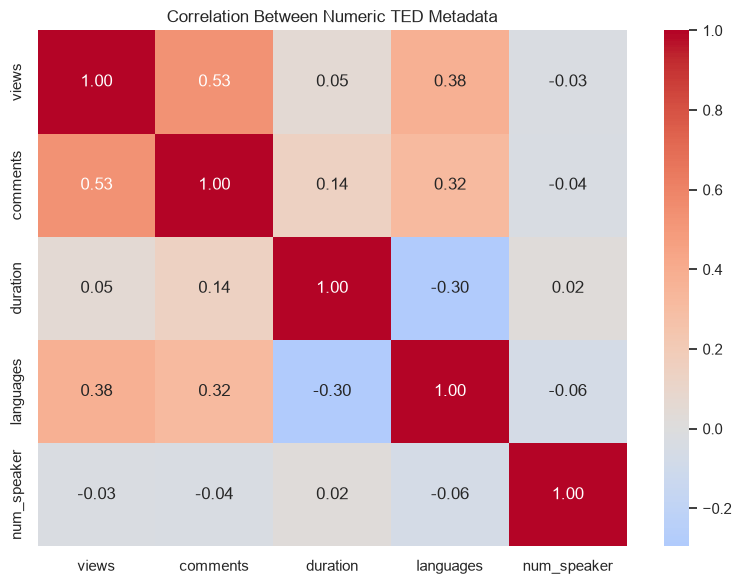

In [8]:
relationship_cols = [c for c in ["views", "comments", "duration", "languages", "num_speaker"]
                     if c in df.columns]
if len(relationship_cols) >= 2:
    corr = df[relationship_cols].corr(numeric_only=True)
    display(corr)

    plt.figure(figsize=(8, 6))
    sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", center=0)
    plt.title("Correlation Between Numeric TED Metadata")
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "05_numeric_correlation.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("Not enough numeric columns for correlation analysis.")

## 9. Publication-date analysis

The archive stores dates as Unix timestamps in seconds. We convert a copy for plotting; the original column remains unchanged in the CSV.

Valid publication dates: 2550


,talk_count
published_date,
2006,50
2007,122
2008,188
2009,222
2010,257
2011,261
2012,306
2013,244
2014,240


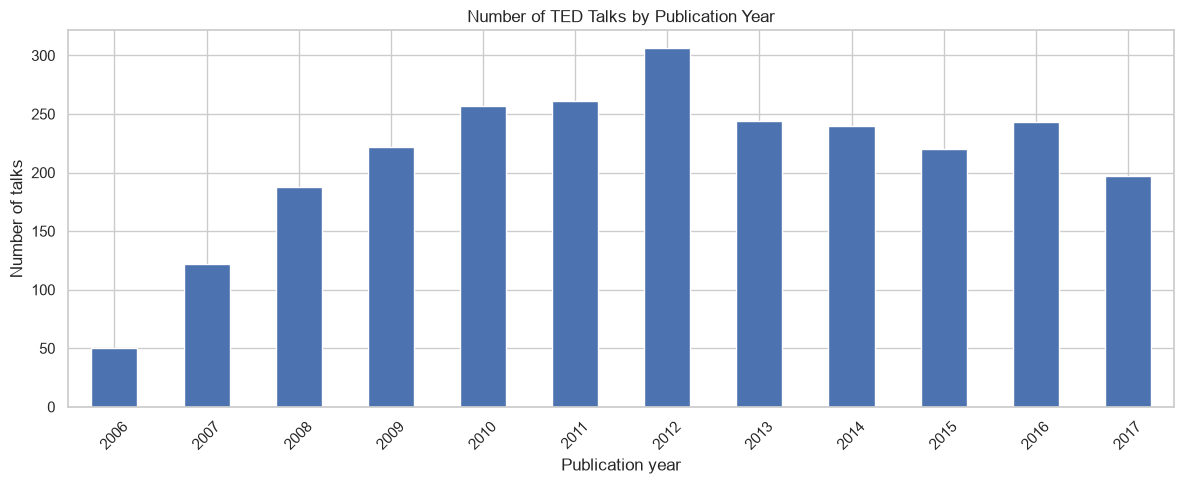

In [9]:
if "published_date" in df.columns:
    published_numeric = pd.to_numeric(df["published_date"], errors="coerce")
    published_dates = pd.to_datetime(published_numeric, unit="s", errors="coerce", utc=True)
    valid_dates = published_dates.dropna()

    print("Valid publication dates:", len(valid_dates))
    if not valid_dates.empty:
        year_counts = valid_dates.dt.year.value_counts().sort_index()
        display(year_counts.rename("talk_count").to_frame())

        plt.figure(figsize=(12, 5))
        year_counts.plot(kind="bar")
        plt.title("Number of TED Talks by Publication Year")
        plt.xlabel("Publication year")
        plt.ylabel("Number of talks")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.savefig(PLOT_DIR / "06_publication_year.png", dpi=300, bbox_inches="tight")
        plt.show()
else:
    print("published_date column is not available.")

## 10. Topic/tag exploration

The `tags` field is stored as a string representation of a Python list in this dataset. We parse it safely with `ast.literal_eval`; this does not modify the original column.

,tag,talk_count
0,technology,727
1,science,567
2,global issues,501
3,culture,486
4,tedx,450
5,design,418
6,business,348
7,entertainment,299
8,health,236
9,innovation,229


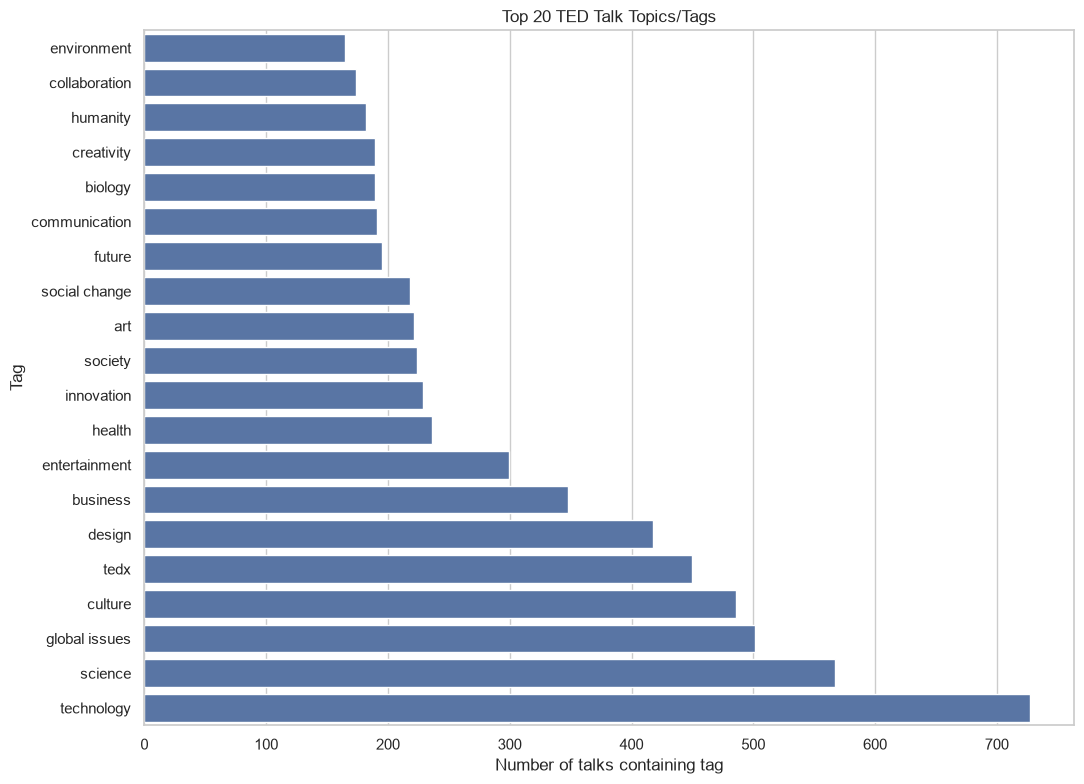

Tags per talk summary:


,tags_per_talk
count,2550.000000
mean,7.511373
std,4.309849
min,1.000000
25%,5.000000
50%,6.000000
75%,9.000000
max,32.000000


In [10]:
def parse_list_field(value):
    if pd.isna(value):
        return []
    if isinstance(value, list):
        return value
    try:
        parsed = ast.literal_eval(str(value))
        return parsed if isinstance(parsed, list) else []
    except (ValueError, SyntaxError):
        # Fallback for simple comma-separated tag strings
        return [x.strip().strip("'\"") for x in str(value).split(",") if x.strip()]

if "tags" in df.columns:
    tags_lists = df["tags"].apply(parse_list_field)
    tag_counter = Counter(
        str(tag).strip().lower()
        for tag_list in tags_lists
        for tag in tag_list
        if str(tag).strip()
    )
    tag_frequency = pd.DataFrame(
        tag_counter.most_common(), columns=["tag", "talk_count"]
    )
    display(tag_frequency.head(20))
    tag_frequency.to_csv(STATS_DIR / "tag_frequency.csv", index=False)

    top_tags = tag_frequency.head(20).sort_values("talk_count")
    plt.figure(figsize=(11, 8))
    sns.barplot(data=top_tags, x="talk_count", y="tag")
    plt.title("Top 20 TED Talk Topics/Tags")
    plt.xlabel("Number of talks containing tag")
    plt.ylabel("Tag")
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "07_top_20_tags.png", dpi=300, bbox_inches="tight")
    plt.show()

    tags_per_talk = tags_lists.apply(len)
    print("Tags per talk summary:")
    display(tags_per_talk.describe().to_frame("tags_per_talk"))
else:
    tags_lists = pd.Series([[]] * len(df), index=df.index)
    print("tags column is not available.")

## 11. Speaker exploration

Unique speakers: 2156


,talk_count
main_speaker,
Hans Rosling,9
Juan Enriquez,7
Rives,6
Marco Tempest,6
Nicholas Negroponte,5
Jacqueline Novogratz,5
Clay Shirky,5
Bill Gates,5
Dan Ariely,5


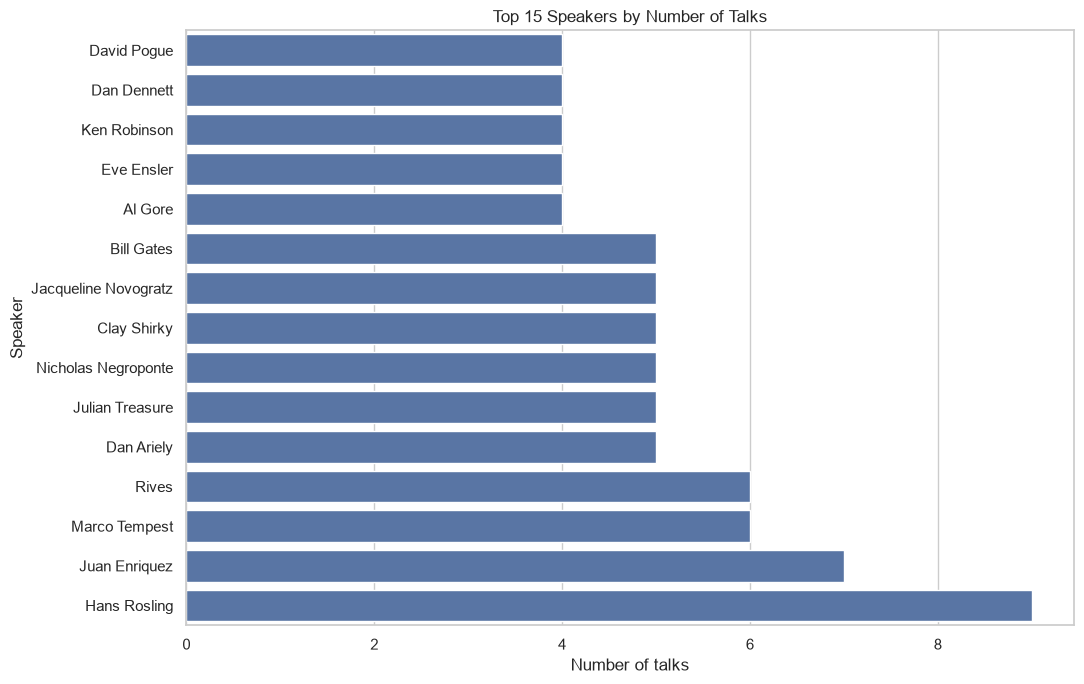

In [11]:
speaker_col = "main_speaker" if "main_speaker" in df.columns else (
    "speaker" if "speaker" in df.columns else None
)

if speaker_col:
    speaker_counts = df[speaker_col].fillna("Unknown").value_counts()
    print("Unique speakers:", df[speaker_col].nunique(dropna=True))
    display(speaker_counts.head(15).rename("talk_count").to_frame())

    top_speakers = speaker_counts.head(15).sort_values()
    plt.figure(figsize=(11, 7))
    sns.barplot(x=top_speakers.values, y=top_speakers.index)
    plt.title("Top 15 Speakers by Number of Talks")
    plt.xlabel("Number of talks")
    plt.ylabel("Speaker")
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "08_top_speakers.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("No speaker column found.")

## 12. Transcript and text-length exploration

Transcript word count is a text statistic, not the actual talk duration. The actual duration is represented by the `duration` field in seconds.

,non_missing_records,missing_records,average_words,median_words,maximum_words
title,2550.0,0.0,6.17,6.0,15.0
description,2550.0,0.0,51.30,48.0,128.0
transcript,2464.0,86.0,2056.82,2046.0,9139.0


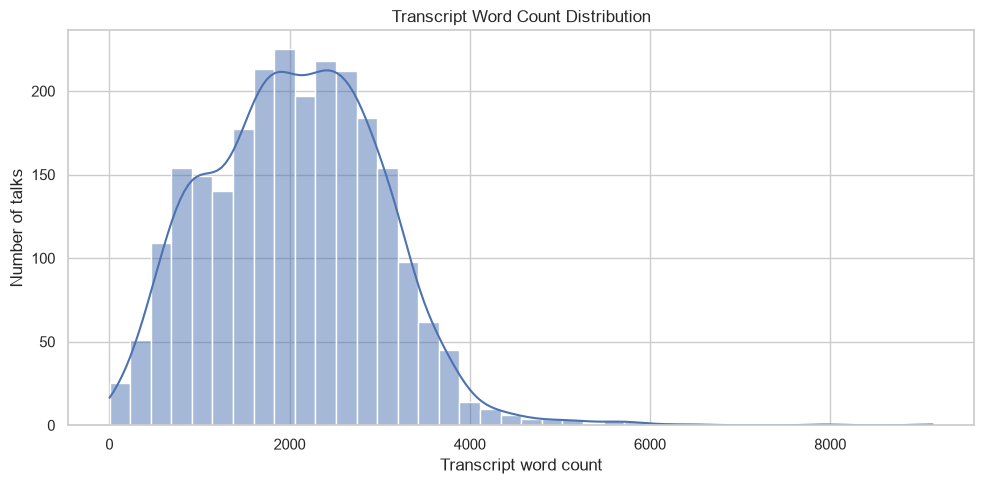

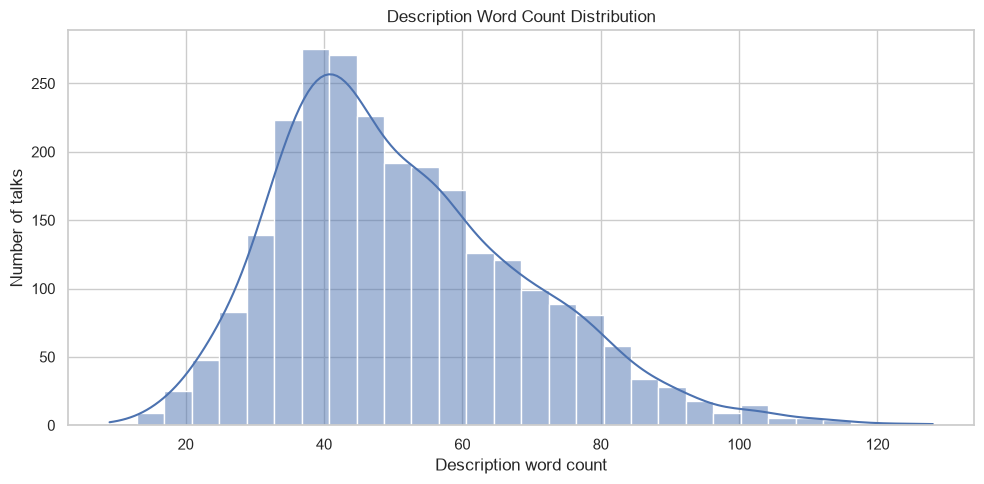

In [12]:
def count_words(value):
    if pd.isna(value):
        return np.nan
    return len(re.findall(r"\b[\w'-]+\b", str(value)))

text_columns = [c for c in ["title", "description", "transcript"] if c in df.columns]
text_summary = {}

for col in text_columns:
    word_counts = df[col].apply(count_words)
    text_summary[col] = {
        "non_missing_records": int(df[col].notna().sum()),
        "missing_records": int(df[col].isna().sum()),
        "average_words": round(word_counts.mean(), 2),
        "median_words": round(word_counts.median(), 2),
        "maximum_words": int(word_counts.max()) if word_counts.notna().any() else 0
    }

text_summary_df = pd.DataFrame(text_summary).T
display(text_summary_df)
text_summary_df.to_csv(STATS_DIR / "text_length_summary.csv")

if "transcript" in df.columns:
    transcript_words = df["transcript"].apply(count_words)
    plt.figure(figsize=(10, 5))
    sns.histplot(transcript_words.dropna(), bins=40, kde=True)
    plt.title("Transcript Word Count Distribution")
    plt.xlabel("Transcript word count")
    plt.ylabel("Number of talks")
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "09_transcript_word_count.png", dpi=300, bbox_inches="tight")
    plt.show()

if "description" in df.columns:
    description_words = df["description"].apply(count_words)
    plt.figure(figsize=(10, 5))
    sns.histplot(description_words.dropna(), bins=30, kde=True)
    plt.title("Description Word Count Distribution")
    plt.xlabel("Description word count")
    plt.ylabel("Number of talks")
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "10_description_word_count.png", dpi=300, bbox_inches="tight")
    plt.show()

## 13. Text vocabulary exploration

This is a basic frequency analysis for understanding the transcript vocabulary. It is not model vectorization. We remove common English stopwords for this descriptive chart only.

,word,frequency
0,people,4385
1,know,4130
2,now,3874
3,going,3721
4,think,3316
5,laughter,2934
6,really,2926
7,see,2873
8,i'm,2752
9,things,2530


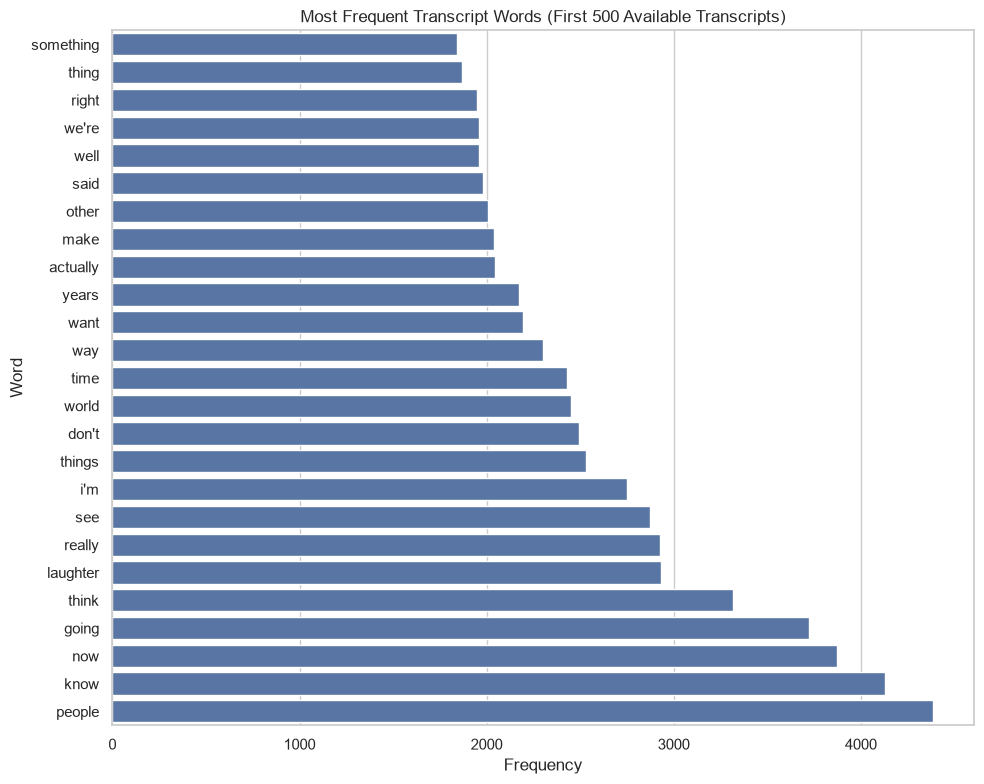

In [13]:
BASIC_STOPWORDS = {
    "the", "and", "for", "that", "with", "you", "this", "was", "are", "have",
    "but", "not", "they", "from", "about", "what", "when", "where", "who",
    "how", "why", "your", "their", "there", "then", "than", "would", "could",
    "should", "into", "just", "like", "been", "were", "will", "it's", "that's",
    "our", "out", "all", "can", "one", "very", "more", "some", "also", "get",
    "got", "has", "had", "its", "his", "her", "him", "them", "these", "those",
    "because", "which", "while", "each", "over", "such", "only", "here"
}

if "transcript" in df.columns:
    words = []
    for text_value in df["transcript"].dropna().astype(str).head(500):
        tokens = re.findall(r"[a-zA-Z']+", text_value.lower())
        words.extend(token for token in tokens
                     if len(token) > 2 and token not in BASIC_STOPWORDS)

    common_words = Counter(words).most_common(25)
    common_words_df = pd.DataFrame(common_words, columns=["word", "frequency"])
    display(common_words_df)

    if not common_words_df.empty:
        plot_data = common_words_df.sort_values("frequency")
        plt.figure(figsize=(10, 8))
        sns.barplot(data=plot_data, x="frequency", y="word")
        plt.title("Most Frequent Transcript Words (First 500 Available Transcripts)")
        plt.xlabel("Frequency")
        plt.ylabel("Word")
        plt.tight_layout()
        plt.savefig(PLOT_DIR / "11_common_transcript_words.png", dpi=300, bbox_inches="tight")
        plt.show()

## 14. Recommendation-system data suitability

This section distinguishes between content metadata and actual individual user interactions. Aggregate views/comments/ratings are not a user–item interaction history.

In [14]:
content_fields = [c for c in ["title", "description", "tags", "transcript", speaker_col]
                  if c and c in df.columns]
interaction_like_fields = [
    c for c in df.columns
    if any(term in c.lower() for term in ["user_id", "viewer_id", "user", "watch_history",
                                          "click", "liked", "saved", "rating_by_user"])
]

print("Potential content fields:", content_fields)
print("Potential individual interaction fields:", interaction_like_fields)

if interaction_like_fields:
    print("Potential interaction columns exist. Inspect their meaning and granularity before collaborative filtering.")
else:
    print(
        "No clear individual user-interaction columns were found. "
        "A genuine user-item interaction matrix cannot be built from this dataset alone."
    )

print("\nRecommendation approach indicated by available data:")
print("- Content-based recommendation: feasible using title, description, tags, and transcript.")
print("- Collaborative filtering: requires individual user interactions such as user_id + talk_id + rating/watch event.")
print("- Views and comments are aggregate talk-level popularity signals, not individual user preferences.")

Potential content fields: ['title', 'description', 'tags', 'transcript', 'main_speaker']
Potential individual interaction fields: []
No clear individual user-interaction columns were found. A genuine user-item interaction matrix cannot be built from this dataset alone.

Recommendation approach indicated by available data:
- Content-based recommendation: feasible using title, description, tags, and transcript.
- Collaborative filtering: requires individual user interactions such as user_id + talk_id + rating/watch event.
- Views and comments are aggregate talk-level popularity signals, not individual user preferences.


## 15. Outlier inspection

Outliers are flagged for investigation, not automatically removed. Popular talks naturally have much higher views than many other talks.

In [15]:
outlier_rows = []
for col in ["views", "comments", "duration"]:
    if col in df.columns:
        series = pd.to_numeric(df[col], errors="coerce").dropna()
        if len(series):
            q1, q3 = series.quantile([0.25, 0.75])
            iqr = q3 - q1
            lower = q1 - 1.5 * iqr
            upper = q3 + 1.5 * iqr
            count = int(((series < lower) | (series > upper)).sum())
            outlier_rows.append({
                "column": col, "q1": q1, "q3": q3, "iqr": iqr,
                "lower_bound": lower, "upper_bound": upper,
                "potential_outlier_count": count
            })

outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)
outlier_summary.to_csv(STATS_DIR / "outlier_summary.csv", index=False)

,column,q1,q3,iqr,lower_bound,upper_bound,potential_outlier_count
0,views,755792.75,1700759.50,944966.75,-661657.375,3118209.625,246
1,comments,63.00,221.75,158.75,-175.125,459.875,200
2,duration,577.00,1046.75,469.75,-127.625,1751.375,28


## 16. Compare available source files (optional)

If the original component files and previously cleaned file are present in `Scraped/Data/Raw` and `Scraped/Data/Processed`, inspect their shapes and duplicate URLs. This is a comparison only; no merging or overwriting occurs.

In [16]:
comparison_paths = {
    "ted_main.csv": TED_MAIN_PATH,
    "transcripts.csv": TRANSCRIPTS_PATH,
    "ted_talks_clean.csv": CLEAN_PATH
}

comparison_rows = []
for label, path in comparison_paths.items():
    if path.exists():
        temp = pd.read_csv(path, low_memory=False)
        row = {
            "file": label,
            "rows": temp.shape[0],
            "columns": temp.shape[1],
            "duplicate_rows": int(temp.duplicated().sum())
        }
        if "url" in temp.columns:
            row["duplicate_urls"] = int(temp["url"].astype("string").str.strip().duplicated().sum())
        comparison_rows.append(row)
    else:
        print(f"Optional file not found: {path}")

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)
comparison_df.to_csv(STATS_DIR / "source_file_comparison.csv", index=False)

Optional file not found: c:\Users\DELL\Desktop\INTERNSHIPS\Infosys_SpringBoard\Ted_Talk_Recommendation\Scraped\Data\Raw\ted_main.csv
Optional file not found: c:\Users\DELL\Desktop\INTERNSHIPS\Infosys_SpringBoard\Ted_Talk_Recommendation\Scraped\Data\Raw\transcripts.csv


,file,rows,columns,duplicate_rows,duplicate_urls
0,ted_talks_clean.csv,2550,33,0,0


## 17. Generate an automated data-quality report

The report records key checks from this notebook and saves them as a text file. It does not change the dataset.

In [17]:
report_lines = [
    "TED TALKS DATA EXPLORATION REPORT",
    "=" * 40,
    f"Dataset file: {MAIN_PATH}",
    f"Rows: {df.shape[0]}",
    f"Columns: {df.shape[1]}",
    f"Exact duplicate rows: {int(df.duplicated().sum())}",
    "",
    "MISSING VALUE SUMMARY:"
]

for _, row in missing_summary.iterrows():
    report_lines.append(
        f"- {row['column']}: {int(row['total_missing_or_empty'])} "
        f"({row['missing_percent']}%)"
    )

report_lines.extend(["", "RECOMMENDATION DATA READINESS:"])
report_lines.append(f"- Content fields available: {', '.join(content_fields)}")
report_lines.append(
    f"- Individual interaction-like columns: {', '.join(interaction_like_fields) if interaction_like_fields else 'None identified'}"
)
report_lines.extend([
    "",
    "IMPORTANT NOTES:",
    "- This notebook performs exploration only.",
    "- Raw data was not modified.",
    "- Transcript word count is not the same as actual talk duration.",
    "- Aggregate views/comments/ratings do not replace individual user-item interactions.",
    "- Missing transcripts should be investigated; do not automatically discard those talks."
])

report_path = REPORT_DIR / "data_quality_report.txt"
report_path.write_text("\n".join(report_lines), encoding="utf-8")
print(report_path.read_text(encoding="utf-8"))

TED TALKS DATA EXPLORATION REPORT
Dataset file: c:\Users\DELL\Desktop\INTERNSHIPS\Infosys_SpringBoard\Ted_Talk_Recommendation\Scraped\Data\Raw\ted_talks.csv
Rows: 2550
Columns: 20
Exact duplicate rows: 0

MISSING VALUE SUMMARY:
- transcript: 86 (3.37%)
- speaker_occupation: 6 (0.24%)
- title: 0 (0.0%)
- talk_id: 0 (0.0%)
- main_speaker: 0 (0.0%)
- description: 0 (0.0%)
- tags: 0 (0.0%)
- related_talks: 0 (0.0%)
- ratings: 0 (0.0%)
- views: 0 (0.0%)
- comments: 0 (0.0%)
- duration: 0 (0.0%)
- published_date: 0 (0.0%)
- event: 0 (0.0%)
- url: 0 (0.0%)
- source: 0 (0.0%)
- film_date: 0 (0.0%)
- languages: 0 (0.0%)
- name: 0 (0.0%)
- num_speaker: 0 (0.0%)

RECOMMENDATION DATA READINESS:
- Content fields available: title, description, tags, transcript, main_speaker
- Individual interaction-like columns: None identified

IMPORTANT NOTES:
- This notebook performs exploration only.
- Raw data was not modified.
- Transcript word count is not the same as actual talk duration.
- Aggregate views/c

## 18. EDA conclusions and hand-off to preprocessing

Use the actual outputs above to complete this section after running all cells.

### Questions to answer
1. How many talks and columns are present?
2. Which columns contain missing values, and what percentage is missing?
3. Are there duplicate records, IDs, or URLs?
4. Which topics/tags are most common?
5. What does the talk-duration distribution look like?
6. How does transcript availability affect recommendation coverage?
7. Which content fields should be used for content-based recommendations?
8. Is there genuine individual user-interaction data for collaborative filtering?

### Recommended hand-off
- Keep the raw dataset unchanged.
- In Notebook 02, create a separate cleaned copy and document each cleaning decision.
- Preserve talks with missing transcripts when title, description, or tags still provide useful content.
- Normalize/parse tags and dates carefully.
- Preserve original text columns and create separate cleaned-text columns.
- Do not fabricate user ratings or user histories.
- Keep TF-IDF/embeddings and the final similarity matrix for Module 3.

## 19. Final validation

Run this final cell after running all previous cells. It confirms the original in-memory dataset was not modified by the exploration workflow.

In [18]:
assert df_original.shape == df.shape, "Dataset shape changed during exploration."
assert list(df_original.columns) == list(df.columns), "Dataset columns changed during exploration."

print("EDA notebook completed.")
print("Raw CSV file was only read; no cleaning or overwriting was performed.")
print("Visualizations saved to:", PLOT_DIR)
print("Statistics saved to:", STATS_DIR)
print("Report saved to:", REPORT_DIR)

EDA notebook completed.
Raw CSV file was only read; no cleaning or overwriting was performed.
Visualizations saved to: c:\Users\DELL\Desktop\INTERNSHIPS\Infosys_SpringBoard\Ted_Talk_Recommendation\Module_2_Data_Exploration_Preprocessing\outputs\visualizations
Statistics saved to: c:\Users\DELL\Desktop\INTERNSHIPS\Infosys_SpringBoard\Ted_Talk_Recommendation\Module_2_Data_Exploration_Preprocessing\outputs\statistics
Report saved to: c:\Users\DELL\Desktop\INTERNSHIPS\Infosys_SpringBoard\Ted_Talk_Recommendation\Module_2_Data_Exploration_Preprocessing\outputs\reports
